# Import Libraries

In [36]:
import geopandas as gpd
from pathlib import Path
import matplotlib.pyplot as plt
import contextily as cx



# Extract Files from Directory

In [37]:
current_dir = Path.cwd()

def find_dataset(filename):
    for directory in [current_dir, *current_dir.parents]:
        matches = list(directory.rglob(filename))
        if matches:
            return matches[0]
    raise FileNotFoundError(f"Could not find {filename} from the notebook location")

hawkercenters_path = find_dataset("hawkercenters.geojson")
parks_naturereserves_path = find_dataset("parks_naturereserves.geojson")
sports_hall_path = find_dataset("sportshall.geojson")

df_hc = gpd.read_file(hawkercenters_path)
df_parks = gpd.read_file(parks_naturereserves_path)
df_sh = gpd.read_file(sports_hall_path)

print(df_hc.shape)
print(df_parks.shape)
print(df_sh.shape)

(129, 21)
(461, 9)
(45, 9)


In [38]:
print("Hawker centres CRS:", df_hc.crs)
print("Parks and nature reserves CRS:", df_parks.crs)
print("Sports Hall CRs:", df_sh.crs)


Hawker centres CRS: EPSG:4326
Parks and nature reserves CRS: EPSG:4326
Sports Hall CRs: EPSG:4326


In [39]:
df_hc = df_hc.to_crs(epsg=3414)
df_parks = df_parks.to_crs(epsg=3414)
df_sh = df_sh.to_crs(epsg=3414)

In [40]:
df_hc.info()
df_sh.info()


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype   
---  ------                        --------------  -----   
 0   OBJECTID                      129 non-null    int32   
 1   LANDXADDRESSPOINT             129 non-null    float64 
 2   LANDYADDRESSPOINT             129 non-null    float64 
 3   ADDRESSBUILDINGNAME           126 non-null    str     
 4   ADDRESSPOSTALCODE             129 non-null    str     
 5   ADDRESSSTREETNAME             129 non-null    str     
 6   DESCRIPTION                   129 non-null    str     
 7   NAME                          129 non-null    str     
 8   PHOTOURL                      111 non-null    str     
 9   ADDRESSBLOCKHOUSENUMBER       129 non-null    str     
 10  STATUS                        129 non-null    str     
 11  AWARDED_DATE                  22 non-null     str     
 12  IMPLEMENTATION_DATE           23 non-null 

In [41]:
df_parks.head()


,OBJECTID_1,L_CODE,NAME,N_RESERVE,INC_CRC,FMEL_UPD_D,SHAPE_1.AREA,SHAPE_1.LEN,geometry
0,117299,PKCR029,VENUS GREEN,0,7A493E6088622B14,20260115000106,2186.802711,189.410958,"POLYGON ((27339.162 37834.726, 27363.515 37854..."
1,117300,NA545,THE INGLEWOOD PG,0,BB4B35C0398BA53A,20260115000106,1781.458102,298.714784,"POLYGON ((27692.713 38121.315, 27681.924 38121..."
2,117301,WJ522,WEST COAST GREEN PLAYGROUND,0,BA0EC4FE59C73616,20260115000106,10220.127826,433.115499,"POLYGON ((19377.295 33178.636, 19377.113 33178..."
3,117302,NP527,PARRY RD PG,0,6889714B3A83B860,20260115000106,3016.170337,274.939181,"POLYGON ((32910.347 38709.878, 32910.312 38709..."
4,117303,WJ523,WEST COAST PLACE PLAYGROUND,0,0D1254C598D611CD,20260115000106,8362.623879,482.769354,"POLYGON ((19611.2 33042.802, 19609.225 33044.7..."


In [42]:
df_sh.head()

,OBJECTID,VENUE,ADDRESSBLOCKHOUSENUMBER,ADDRESSSTREETNAME,POSTAL_CODE,DETAILS,INC_CRC,FMEL_UPD_D,geometry
0,335,Bukit Canberra Sport Centre,21,Canberra Link,756973,https://www.activesgcircle.gov.sg/facilities,87E1198E4E7B1323,20241024152749,POINT (26825.402 47767.125)
1,336,Bukit Gombak Sport Centre,810,Bukit Batok West Avenue 5,659088,https://www.activesgcircle.gov.sg/facilities,1C45D8B5C695F969,20241024152749,POINT (18969.13 37985.391)
2,337,Burghley Squash & Tennis Centre,43,Burghley Drive,559020,https://www.activesgcircle.gov.sg/facilities,4B488140BE206850,20241024152749,POINT (31023.477 37940.062)
3,338,Choa Chu Kang Sport Centre,1,Choa Chu Kang Street 53,689236,https://www.activesgcircle.gov.sg/facilities,8D69CA472FF51A58,20241024152749,POINT (18496.331 41398.487)
4,339,Clementi Sport Centre,518,Clementi Avenue 3,129907,https://www.activesgcircle.gov.sg/facilities,EF093371C280522D,20241024152749,POINT (20381.363 32590.997)


In [43]:
df_hc=df_hc[["NAME","geometry"]]

In [44]:
df_sh = df_sh[["VENUE","geometry"]]

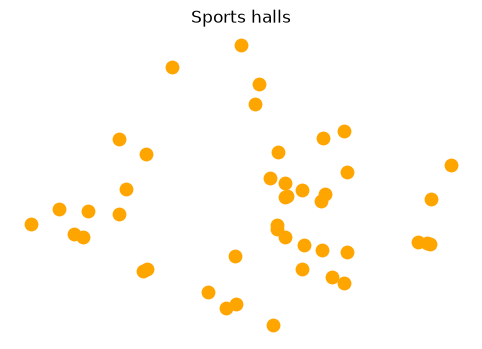

In [45]:
df_sh_global = df_sh.to_crs(epsg=4326)
ax = df_sh_global.plot(
    figsize=(6, 4),
    color="orange",
    markersize=80
)

ax.set_title("Sports halls")
ax.set_axis_off()
plt.show()

In [46]:
df_parks=df_parks[["NAME","geometry"]]

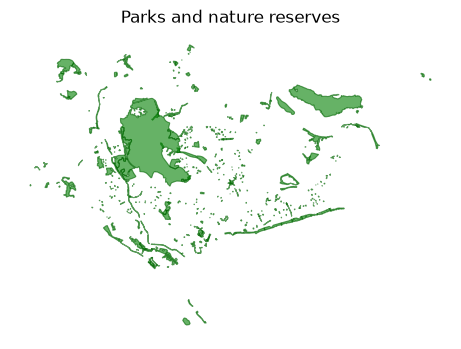

In [47]:
df_parks_global = df_parks.to_crs(epsg=4326)
ax = df_parks_global.plot(
    figsize=(6, 4),
    facecolor="green",
    edgecolor="darkgreen",
    linewidth=0.8,
    alpha=0.6
)

ax.set_title("Parks and nature reserves")
ax.set_axis_off()
plt.show()

# Plot Points on Map

## Sports Hall

In [48]:
df_sh.explore(
    tiles="OpenStreetMap",
    marker_kwds={
        "radius": 5,
        "color": "orange",
        "fill": True,
        "fill_color": "red",
        "fill_opacity": 1
    }
)

## Hawker Centres

In [49]:
df_hc.explore(
    tiles="OpenStreetMap",
    marker_kwds={
        "radius": 10,
        "color": "red",
        "fill": True,
        "fill_color": "red",
        "fill_opacity": 0.7
    }
)

## Parks

In [50]:
df_parks.explore(
    tiles="OpenStreetMap",
    style_kwds={
        "color": "green",
        "fillColor": "green",
        "fillOpacity": 0.7,
        "weight": 1
    }
)